# HW2



## Suggested runtime

- **Colab GPU** is recommended.
- Variant A runs quickly even in fast mode.
- Variant B is heavier, so the notebook uses small defaults.

It is possible to switch `FAST_DEV_RUN_A` / `FAST_DEV_RUN_B` to `False` for full experiments.


In [1]:
import os, json, math, random, time, zipfile, shutil, hashlib, urllib.request
from pathlib import Path
from dataclasses import dataclass
from typing import Dict, List, Tuple, Optional

import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from PIL import Image, ImageEnhance

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split, Subset
import torchvision
import torchvision.transforms as T

from IPython.display import display

try:
    import pandas as pd
    HAS_PANDAS = True
except Exception:
    HAS_PANDAS = False

try:
    from sklearn.metrics import confusion_matrix
    HAS_SKLEARN = True
except Exception:
    HAS_SKLEARN = False

try:
    import scipy
    from scipy.optimize import linear_sum_assignment
    HAS_SCIPY = True
except Exception:
    HAS_SCIPY = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("numpy:", np.__version__)
print("scipy available:", HAS_SCIPY)
print("sklearn available:", HAS_SKLEARN)
print("device:", device)

SEED = 42

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True

seed_everything(SEED)

os.makedirs("outputs/variant_a", exist_ok=True)
os.makedirs("outputs/variant_b", exist_ok=True)
os.makedirs("data", exist_ok=True)

try:
    from google.colab import files
    IN_COLAB = True
except Exception:
    IN_COLAB = False

print("IN_COLAB:", IN_COLAB)

torch: 2.10.0+cu128
torchvision: 0.25.0+cu128
numpy: 2.0.2
scipy available: True
sklearn available: True
device: cuda
IN_COLAB: True


In [2]:
RUN_VARIANT_A = True
RUN_VARIANT_B = True

DATASET_A = "cifar10"
IMG_SIZE_A = 64
FAST_DEV_RUN_A = False
EPOCHS_A = 5 if FAST_DEV_RUN_A else 10
BATCH_SIZE_A = 192 if torch.cuda.is_available() else 128
LR_A = 5e-4
WEIGHT_DECAY_A = 0.05
LABEL_SMOOTHING_A = 0.1

VIT_CONFIGS = [
    dict(name="vit_p8_d2_dim128_cls", patch=8, depth=2, dim=128, heads=4, mlp_ratio=4.0, use_cls=True),
    dict(name="vit_p16_d3_dim192_mean", patch=16, depth=3, dim=192, heads=6, mlp_ratio=4.0, use_cls=False),
]

DATASET_B = "penn_fudan"
IMG_SIZE_B = 256
FAST_DEV_RUN_B = False
EPOCHS_B = 4 if FAST_DEV_RUN_B else 18
BATCH_SIZE_B = 8 if torch.cuda.is_available() else 4
LR_B = 4e-4
WEIGHT_DECAY_B = 1e-4

QUERY_CONFIGS = [
    dict(name="q10_p8_d2_dim128_boxonly", patch=8, num_queries=10, dim=128, heads=4, dec_layers=2, use_mask=False),
    dict(name="q12_p8_d2_dim128_boxmask", patch=8, num_queries=12, dim=128, heads=4, dec_layers=2, use_mask=True),
]

NUM_WORKERS = 0

torch.backends.cudnn.benchmark = bool(torch.cuda.is_available())

In [3]:
def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def ensure_dir(path: str):
    Path(path).mkdir(parents=True, exist_ok=True)

def format_seconds(seconds: float) -> str:
    seconds = int(max(0, round(float(seconds))))
    h, rem = divmod(seconds, 3600)
    m, s = divmod(rem, 60)
    if h > 0:
        return f"{h}h {m:02d}m {s:02d}s"
    if m > 0:
        return f"{m}m {s:02d}s"
    return f"{s}s"

def estimate_epoch_seconds(task: str, n_batches: int, params_m: float = 1.0, seq_len: int = None, num_queries: int = None, visual_tokens: int = None) -> float:
    if task == "A":
        base = 0.11 if device.type == "cuda" else 0.75
        complexity = 1.0 + 0.10 * max(0.0, params_m - 0.3) + 0.0025 * max(0, (seq_len or 64) - 64)
    else:
        base = 0.24 if device.type == "cuda" else 1.50
        complexity = 1.0 + 0.15 * max(0.0, params_m - 0.4) + 0.004 * max(0, (num_queries or 25) - 25) + 0.00045 * max(0, (visual_tokens or 256) - 256)
    return n_batches * base * complexity

def print_runtime_hint(name: str, seconds: float):
    print(f"Approx runtime for {name} on {device.type.upper()}: ~{format_seconds(seconds)} (heuristic estimate)")

class StageTimer:
    def __init__(self, name: str):
        self.name = name
        self.start = None
        self.elapsed = None
    def __enter__(self):
        self.start = time.perf_counter()
        print(f"[{self.name}] started")
        return self
    def __exit__(self, exc_type, exc, tb):
        self.elapsed = time.perf_counter() - self.start
        print(f"[{self.name}] finished in {format_seconds(self.elapsed)}")

def save_figure(path: str):
    ensure_dir(Path(path).parent.as_posix())
    fig = plt.gcf()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("saved:", path)
    plt.show()
    plt.close(fig)

def show_and_close():
    plt.show()
    plt.close("all")

def safe_torch_save(obj, path: str):
    ensure_dir(Path(path).parent.as_posix())
    torch.save(obj, path)
    print("saved:", path)

def safe_torch_load(path: str, device):
    return torch.load(path, map_location=device)

def show_images_grid(images, titles=None, ncols: int = 6, figsize=(12, 6), denorm_mean=None, denorm_std=None):
    if torch.is_tensor(images):
        imgs = images.detach().cpu()
        if imgs.ndim == 3:
            imgs = imgs.unsqueeze(0)
    else:
        imgs = torch.as_tensor(np.array(images))
        if imgs.ndim == 3:
            imgs = imgs.unsqueeze(0)

    n = int(imgs.shape[0])
    ncols = max(1, min(ncols, n))
    nrows = int(math.ceil(n / ncols))
    plt.figure(figsize=figsize)

    for i in range(n):
        ax = plt.subplot(nrows, ncols, i + 1)
        im = imgs[i]
        if im.ndim == 3 and im.shape[0] in (1, 3):
            im = im.permute(1, 2, 0).float().numpy()
        else:
            im = im.float().numpy()

        if denorm_mean is not None and denorm_std is not None and im.ndim == 3 and im.shape[-1] == len(denorm_mean):
            mean = np.array(denorm_mean, dtype=np.float32).reshape(1, 1, -1)
            std = np.array(denorm_std, dtype=np.float32).reshape(1, 1, -1)
            im = im * std + mean

        if im.ndim == 3:
            im = np.clip(im, 0.0, 1.0)
            ax.imshow(im)
        else:
            ax.imshow(im, cmap="gray")
        if titles is not None and i < len(titles):
            ax.set_title(str(titles[i]), fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    show_and_close()

def accuracy_top1(logits: torch.Tensor, targets: torch.Tensor) -> float:
    pred = logits.argmax(dim=1)
    return float((pred == targets).float().mean().item())

def estimate_self_attention_cost(seq_len: int, dim: int, num_heads: int) -> Dict[str, float]:
    qkv_proj = 3.0 * seq_len * dim * dim
    attn_scores = float(num_heads) * (seq_len ** 2) * (dim / max(1, num_heads))
    attn_weighted_sum = float(num_heads) * (seq_len ** 2) * (dim / max(1, num_heads))
    out_proj = 1.0 * seq_len * dim * dim
    total = qkv_proj + attn_scores + attn_weighted_sum + out_proj
    return {
        "seq_len": int(seq_len),
        "dim": int(dim),
        "num_heads": int(num_heads),
        "approx_flops": float(total),
        "approx_mflops": float(total / 1e6),
        "approx_ops": float(total),
        "attn_weights_mem_mb": float((num_heads * (seq_len ** 2) * 4) / (1024 ** 2)),
    }

def download_file(url: str, out_path: str, min_bytes: int = 1, retries: int = 3, timeout: int = 60):
    ensure_dir(Path(out_path).parent.as_posix())
    last_err = None
    for attempt in range(retries):
        try:
            with urllib.request.urlopen(url, timeout=timeout) as resp, open(out_path, "wb") as f:
                shutil.copyfileobj(resp, f)
            if os.path.getsize(out_path) < min_bytes:
                raise RuntimeError(f"Downloaded file too small: {out_path}")
            print("downloaded:", out_path)
            return out_path
        except Exception as e:
            last_err = e
            if os.path.exists(out_path):
                try:
                    os.remove(out_path)
                except Exception:
                    pass
            time.sleep(1.0 + attempt)
    raise RuntimeError(f"Failed to download {url}: {last_err}")

def extract_zip(zip_path: str, out_dir: str):
    ensure_dir(out_dir)
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(out_dir)

# Variant A — Mini Vision Transformer for Classification

This section implements:
- patch embedding
- positional embeddings
- class token or mean pooling
- multiple self-attention blocks
- architecture comparisons
- error analysis


100%|██████████| 170M/170M [00:03<00:00, 43.1MB/s]


Dataset A: cifar10 | train: 45000 val: 5000 test: 10000 classes: 10
Batch: torch.Size([192, 3, 64, 64]) torch.Size([192])


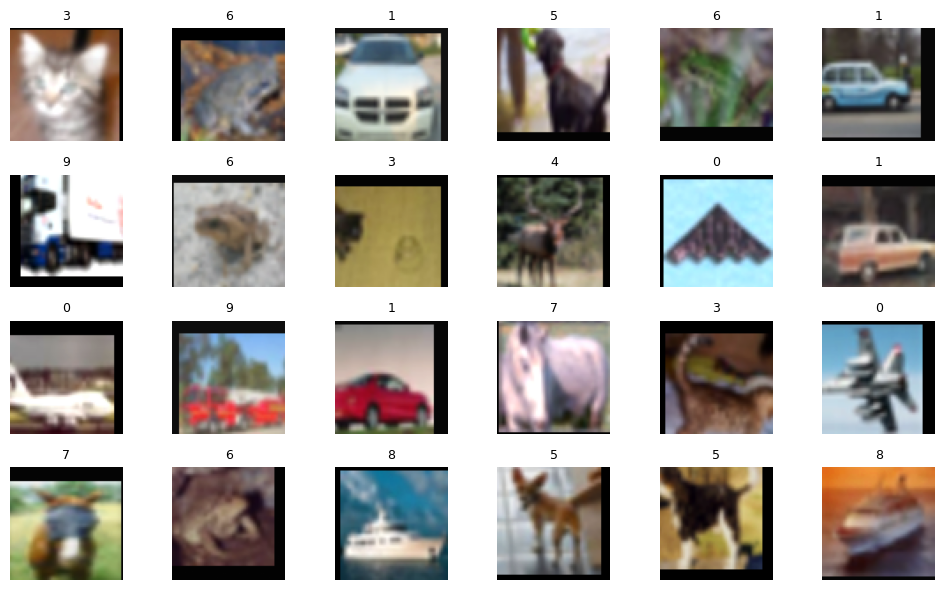

In [4]:
def get_classification_datasets(
    name: str,
    img_size: int,
    root: str = "data",
    val_fraction: float = 0.1,
):
    os.makedirs(root, exist_ok=True)

    cifar_mean = (0.4914, 0.4822, 0.4465)
    cifar_std = (0.2470, 0.2435, 0.2616)

    train_tf = T.Compose([
        T.Resize((img_size, img_size)),
        T.RandomCrop(img_size, padding=8),
        T.RandomHorizontalFlip(p=0.5),
        T.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.03),
        T.ToTensor(),
        T.Normalize(cifar_mean, cifar_std),
    ])
    test_tf = T.Compose([
        T.Resize((img_size, img_size)),
        T.ToTensor(),
        T.Normalize(cifar_mean, cifar_std),
    ])

    name = name.lower().strip()
    if name == "cifar10":
        full_train = torchvision.datasets.CIFAR10(root=root, train=True, transform=train_tf, download=True)
        test_ds = torchvision.datasets.CIFAR10(root=root, train=False, transform=test_tf, download=True)
        num_classes = 10
        class_names = list(full_train.classes)
    elif name == "cifar100":
        full_train = torchvision.datasets.CIFAR100(root=root, train=True, transform=train_tf, download=True)
        test_ds = torchvision.datasets.CIFAR100(root=root, train=False, transform=test_tf, download=True)
        num_classes = 100
        class_names = list(full_train.classes)
    elif name == "oxford_pets":
        full_train = torchvision.datasets.OxfordIIITPet(
            root=root, split="trainval", target_types="category", transform=train_tf, download=True
        )
        test_ds = torchvision.datasets.OxfordIIITPet(
            root=root, split="test", target_types="category", transform=test_tf, download=True
        )
        num_classes = 37
        class_names = [f"class_{i}" for i in range(num_classes)]
    elif name == "flowers102":
        full_train = torchvision.datasets.Flowers102(root=root, split="train", transform=train_tf, download=True)
        val_ds = torchvision.datasets.Flowers102(root=root, split="val", transform=test_tf, download=True)
        test_ds = torchvision.datasets.Flowers102(root=root, split="test", transform=test_tf, download=True)
        num_classes = 102
        class_names = [f"class_{i}" for i in range(num_classes)]
        return full_train, val_ds, test_ds, num_classes, class_names
    else:
        raise ValueError(f"Unknown dataset A: {name}")

    n = len(full_train)
    n_val = int(round(n * val_fraction))
    n_train = n - n_val
    g = torch.Generator().manual_seed(SEED)
    train_ds, val_ds = random_split(full_train, [n_train, n_val], generator=g)
    return train_ds, val_ds, test_ds, num_classes, class_names

trainA, valA, testA, num_classes_A, class_names_A = get_classification_datasets(
    DATASET_A, img_size=IMG_SIZE_A, root="data", val_fraction=0.1
)

def maybe_subset(ds, max_items=None):
    if max_items is None or len(ds) <= max_items:
        return ds
    idx = list(range(len(ds)))[:max_items]
    return Subset(ds, idx)

MAX_TRAIN_A = 15000 if FAST_DEV_RUN_A else None
MAX_VAL_A = 3000 if FAST_DEV_RUN_A else None

trainA_small = maybe_subset(trainA, MAX_TRAIN_A)
valA_small = maybe_subset(valA, MAX_VAL_A)

loader_trainA = DataLoader(trainA_small, batch_size=BATCH_SIZE_A, shuffle=True, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
loader_valA = DataLoader(valA_small, batch_size=BATCH_SIZE_A, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

print("Dataset A:", DATASET_A, "| train:", len(trainA_small), "val:", len(valA_small), "test:", len(testA), "classes:", num_classes_A)

xb, yb = next(iter(loader_trainA))
print("Batch:", xb.shape, yb.shape)
show_images_grid(xb[:24].cpu() * torch.tensor((0.2470, 0.2435, 0.2616)).view(1,3,1,1) + torch.tensor((0.4914, 0.4822, 0.4465)).view(1,3,1,1), titles=[str(int(t)) for t in yb[:24]], ncols=6, figsize=(10, 6))

In [5]:
class PatchEmbed(nn.Module):
    def __init__(self, in_chans: int, embed_dim: int, patch_size: int):
        super().__init__()
        self.patch_size = patch_size
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x: torch.Tensor):
        y = self.proj(x)
        Hp, Wp = y.shape[-2], y.shape[-1]
        tokens = y.flatten(2).transpose(1, 2)
        return tokens, (Hp, Wp)

class MLP(nn.Module):
    def __init__(self, dim: int, mlp_ratio: float = 4.0, drop: float = 0.0):
        super().__init__()
        hidden = int(dim * mlp_ratio)
        self.fc1 = nn.Linear(dim, hidden)
        self.fc2 = nn.Linear(hidden, dim)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = self.fc1(x)
        x = F.gelu(x)
        x = self.drop(x)
        x = self.fc2(x)
        x = self.drop(x)
        return x

class EncoderBlock(nn.Module):
    def __init__(self, dim: int, heads: int, mlp_ratio: float = 4.0, attn_drop: float = 0.0, drop: float = 0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, dropout=attn_drop, batch_first=True)
        self.drop = nn.Dropout(drop)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = MLP(dim, mlp_ratio=mlp_ratio, drop=drop)

    def forward(self, x: torch.Tensor, return_attn: bool = False):
        xn = self.norm1(x)
        attn_out, attn_w = self.attn(
            xn, xn, xn,
            need_weights=return_attn,
            average_attn_weights=False
        )
        x = x + self.drop(attn_out)
        x = x + self.drop(self.mlp(self.norm2(x)))
        return x, attn_w if return_attn else None

class MiniViT(nn.Module):
    def __init__(
        self,
        image_size: int,
        patch_size: int,
        in_chans: int,
        num_classes: int,
        dim: int,
        depth: int,
        heads: int,
        mlp_ratio: float = 4.0,
        use_cls: bool = True,
        drop: float = 0.0,
    ):
        super().__init__()
        self.image_size = image_size
        self.patch_size = patch_size
        self.use_cls = use_cls
        self.embed = PatchEmbed(in_chans=in_chans, embed_dim=dim, patch_size=patch_size)
        self.pos_embed = None
        self.pos_drop = nn.Dropout(drop)

        if use_cls:
            self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        else:
            self.cls_token = None

        self.blocks = nn.ModuleList([
            EncoderBlock(dim=dim, heads=heads, mlp_ratio=mlp_ratio, drop=drop) for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, num_classes)

        nn.init.trunc_normal_(self.head.weight, std=0.02)
        nn.init.zeros_(self.head.bias)
        if self.cls_token is not None:
            nn.init.trunc_normal_(self.cls_token, std=0.02)

    def _build_pos_embed(self, n_tokens: int, dim: int, device):
        self.pos_embed = nn.Parameter(torch.zeros(1, n_tokens, dim, device=device))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward(self, x: torch.Tensor, return_attn: bool = False):
        tokens, (Hp, Wp) = self.embed(x)
        B, N, D = tokens.shape

        if self.use_cls:
            cls = self.cls_token.expand(B, -1, -1)
            tokens = torch.cat([cls, tokens], dim=1)
            N_total = N + 1
        else:
            N_total = N

        if self.pos_embed is None or self.pos_embed.shape[1] != N_total:
            self._build_pos_embed(n_tokens=N_total, dim=D, device=tokens.device)

        tokens = self.pos_drop(tokens + self.pos_embed)

        attn_maps = []
        for i, blk in enumerate(self.blocks):
            tokens, attn = blk(tokens, return_attn=(return_attn and i == 0))
            if attn is not None:
                attn_maps.append(attn)

        tokens = self.norm(tokens)
        pooled = tokens[:, 0] if self.use_cls else tokens.mean(dim=1)
        logits = self.head(pooled)

        info = {"Hp": Hp, "Wp": Wp, "seq_len": int(N_total)}
        if return_attn and attn_maps:
            info["attn_first_block"] = attn_maps[0].detach()
        return logits, info

In [6]:
def train_one_epoch_classification(model, loader, optimizer, scaler=None):
    model.train()
    losses, accs = [], []
    for xb, yb in tqdm(loader, desc="trainA", leave=False):
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=(scaler is not None and device.type == "cuda")):
            logits, _ = model(xb, return_attn=False)
            loss = F.cross_entropy(logits, yb, label_smoothing=LABEL_SMOOTHING_A)

        if scaler is None or device.type != "cuda":
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        else:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

        losses.append(loss.item())
        accs.append(accuracy_top1(logits.detach(), yb.detach()))
    return float(np.mean(losses)), float(np.mean(accs))

@torch.no_grad()
def eval_classification(model, loader):
    model.eval()
    losses, accs = [], []
    all_preds, all_targets = [], []
    for xb, yb in tqdm(loader, desc="evalA", leave=False):
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)
        logits, _ = model(xb, return_attn=False)
        loss = F.cross_entropy(logits, yb)
        losses.append(loss.item())
        accs.append(accuracy_top1(logits, yb))
        all_preds.append(logits.argmax(dim=1).detach().cpu())
        all_targets.append(yb.detach().cpu())
    preds = torch.cat(all_preds).numpy()
    targets = torch.cat(all_targets).numpy()
    return float(np.mean(losses)), float(np.mean(accs)), preds, targets

def run_vit_experiment(cfg: Dict):
    model = MiniViT(
        image_size=IMG_SIZE_A,
        patch_size=cfg["patch"],
        in_chans=3,
        num_classes=num_classes_A,
        dim=cfg["dim"],
        depth=cfg["depth"],
        heads=cfg["heads"],
        mlp_ratio=cfg["mlp_ratio"],
        use_cls=cfg["use_cls"],
        drop=0.1,
    ).to(device)

    params = count_parameters(model)
    xb, _ = next(iter(loader_valA))
    xb = xb.to(device)
    with torch.no_grad():
        _, info = model(xb[:2], return_attn=False)
    seq_len = info["seq_len"]
    cost = estimate_self_attention_cost(seq_len=seq_len, dim=cfg["dim"], num_heads=cfg["heads"])

    est_epoch_sec = estimate_epoch_seconds("A", len(loader_trainA) + len(loader_valA), params_m=params / 1e6, seq_len=seq_len)
    print_runtime_hint(f"Variant A / {cfg['name']}", est_epoch_sec * EPOCHS_A)

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR_A, weight_decay=WEIGHT_DECAY_A)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_A)
    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc = -1.0
    best_state = None
    exp_start = time.perf_counter()
    epoch_times = []

    for epoch in range(1, EPOCHS_A + 1):
        epoch_start = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch_classification(model, loader_trainA, optimizer, scaler=scaler)
        va_loss, va_acc, _, _ = eval_classification(model, loader_valA)
        scheduler.step()
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        epoch_elapsed = time.perf_counter() - epoch_start
        epoch_times.append(epoch_elapsed)
        eta = np.mean(epoch_times) * max(0, EPOCHS_A - epoch)
        print(f"[{cfg['name']}] epoch {epoch:02d}/{EPOCHS_A} | train_acc={tr_acc:.3f} val_acc={va_acc:.3f} | epoch_time={format_seconds(epoch_elapsed)} | eta={format_seconds(eta)}")

    if best_state is not None:
        model.load_state_dict(best_state)

    va_loss, va_acc, preds, targets = eval_classification(model, loader_valA)
    print(f"[{cfg['name']}] total elapsed: {format_seconds(time.perf_counter() - exp_start)}")

    return {
        "name": cfg["name"],
        "patch": cfg["patch"],
        "depth": cfg["depth"],
        "dim": cfg["dim"],
        "heads": cfg["heads"],
        "use_cls": cfg["use_cls"],
        "params": params,
        "seq_len": seq_len,
        "attn_mem_mb": cost["attn_weights_mem_mb"],
        "approx_ops": cost["approx_ops"],
        "val_acc": va_acc,
        "history": history,
        "preds": preds,
        "targets": targets,
        "state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
    }

Approx runtime for Variant A / vit_p8_d2_dim128_cls on CUDA: ~4m 52s (heuristic estimate)


trainA:   0%|          | 0/235 [00:00<?, ?it/s]

evalA:   0%|          | 0/27 [00:00<?, ?it/s]

[vit_p8_d2_dim128_cls] epoch 01/10 | train_acc=0.309 val_acc=0.361 | epoch_time=1m 13s | eta=10m 56s


trainA:   0%|          | 0/235 [00:00<?, ?it/s]

...

[vit_p16_d3_dim192_mean] epoch 10/10 | train_acc=0.541 val_acc=0.535 | epoch_time=1m 10s | eta=0s


evalA:   0%|          | 0/27 [00:00<?, ?it/s]

[vit_p16_d3_dim192_mean] total elapsed: 11m 49s


,name,patch,depth,dim,heads,use_cls,params,seq_len,attn_mem_mb,approx_ops,val_acc
0,vit_p8_d2_dim128_cls,8,2,128,4,True,422922,65,0.064,5341440,0.5966
1,vit_p16_d3_dim192_mean,16,3,192,6,False,1484554,16,0.006,2457600,0.5320


saved: outputs/variant_a/curve_vit_p8_d2_dim128_cls.png


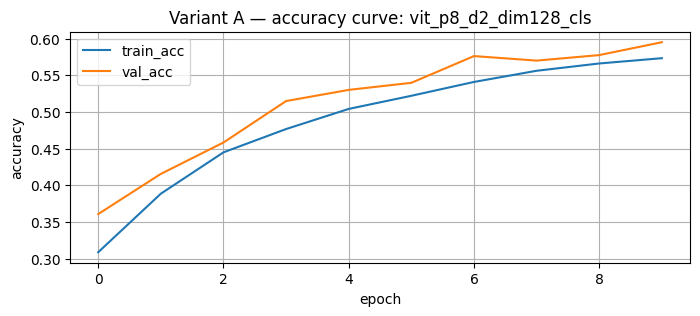

saved: outputs/variant_a/curve_vit_p16_d3_dim192_mean.png


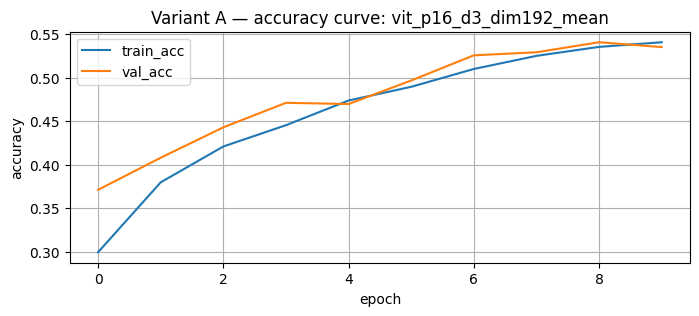

In [7]:
results_A = []
if RUN_VARIANT_A:
    for cfg in VIT_CONFIGS:
        out = run_vit_experiment(cfg)
        results_A.append(out)

    rows = []
    for r in results_A:
        rows.append({
            "name": r["name"],
            "patch": r["patch"],
            "depth": r["depth"],
            "dim": r["dim"],
            "heads": r["heads"],
            "use_cls": r["use_cls"],
            "params": r["params"],
            "seq_len": r["seq_len"],
            "attn_mem_mb": round(r["attn_mem_mb"], 3),
            "approx_ops": int(r["approx_ops"]),
            "val_acc": round(r["val_acc"], 4),
        })

    if HAS_PANDAS:
        dfA = pd.DataFrame(rows).sort_values("val_acc", ascending=False)
        display(dfA)
        dfA.to_csv("outputs/variant_a/results_a.csv", index=False)
    else:
        print(rows)

    for r in results_A:
        h = r["history"]
        plt.figure(figsize=(8, 3))
        plt.plot(h["train_acc"], label="train_acc")
        plt.plot(h["val_acc"], label="val_acc")
        plt.title(f"Variant A — accuracy curve: {r['name']}")
        plt.xlabel("epoch")
        plt.ylabel("accuracy")
        plt.grid(True)
        plt.legend()
        save_figure(f"outputs/variant_a/curve_{r['name']}.png")
        show_and_close()

saved: outputs/variant_a/tokenization_example.png


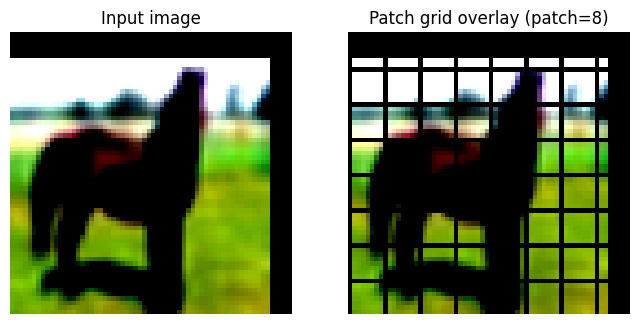

saved: outputs/variant_a/confusion_matrix.png


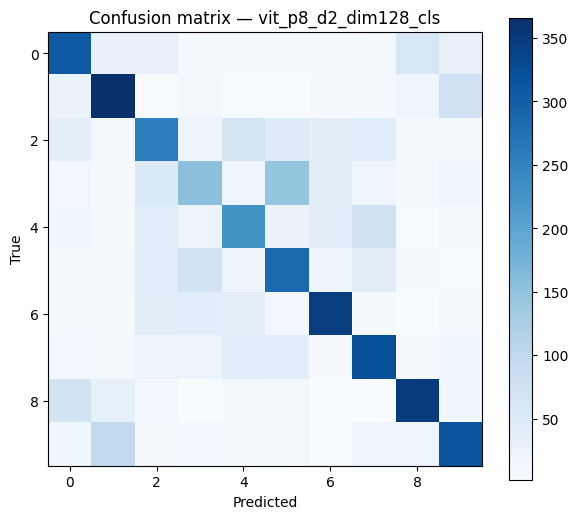

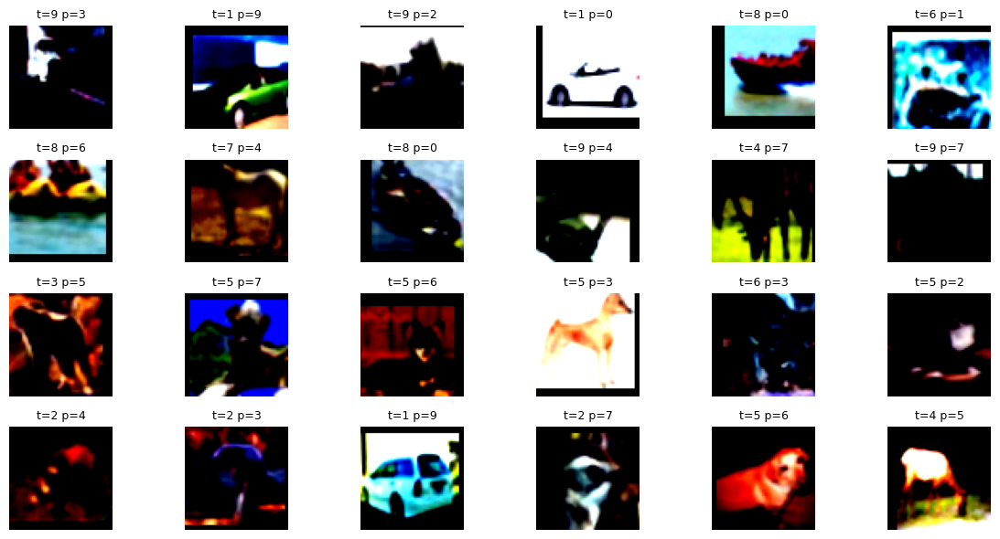

In [8]:
def overlay_patch_grid(img: np.ndarray, patch_size: int):
    H, W = img.shape[:2]
    vis = img.copy()
    for y in range(0, H, patch_size):
        vis[y:y+1, :, :] = 0.0
    for x in range(0, W, patch_size):
        vis[:, x:x+1, :] = 0.0
    return vis

if RUN_VARIANT_A and results_A:
    xb, yb = next(iter(loader_valA))
    img = xb[0].permute(1, 2, 0).numpy()
    patch = VIT_CONFIGS[0]["patch"]
    vis = overlay_patch_grid(img, patch_size=patch)

    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Input image")
    plt.axis("off")
    plt.subplot(1, 2, 2)
    plt.imshow(vis)
    plt.title(f"Patch grid overlay (patch={patch})")
    plt.axis("off")
    save_figure("outputs/variant_a/tokenization_example.png")
    show_and_close()

    bestA = max(results_A, key=lambda r: r["val_acc"])
    preds = bestA["preds"]
    targets = bestA["targets"]

    if HAS_SKLEARN:
        cm = confusion_matrix(targets, preds, labels=list(range(num_classes_A)))
        plt.figure(figsize=(7, 6))
        plt.imshow(cm, cmap="Blues")
        plt.title(f"Confusion matrix — {bestA['name']}")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.colorbar()
        save_figure("outputs/variant_a/confusion_matrix.png")
        show_and_close()

    @torch.no_grad()
    def collect_misclassified(result_row: Dict, max_items: int = 24):
        cfg = next(c for c in VIT_CONFIGS if c["name"] == result_row["name"])
        model = MiniViT(
            image_size=IMG_SIZE_A, patch_size=cfg["patch"], in_chans=3, num_classes=num_classes_A,
            dim=cfg["dim"], depth=cfg["depth"], heads=cfg["heads"], mlp_ratio=cfg["mlp_ratio"], use_cls=cfg["use_cls"], drop=0.0
        ).to(device)
        state_dict = result_row["state_dict"]
        if "pos_embed" in state_dict:
            model._build_pos_embed(int(state_dict["pos_embed"].shape[1]), int(state_dict["pos_embed"].shape[2]), device)
        model.load_state_dict(state_dict)
        model.eval()

        bad_imgs, bad_titles = [], []
        for xb, yb in loader_valA:
            xb = xb.to(device)
            yb = yb.to(device)
            logits, _ = model(xb, return_attn=False)
            pred = logits.argmax(dim=1)
            mask = pred != yb
            if mask.any():
                sel = xb[mask].detach().cpu()
                sel_pred = pred[mask].detach().cpu().numpy()
                sel_true = yb[mask].detach().cpu().numpy()
                for i in range(sel.shape[0]):
                    bad_imgs.append(sel[i])
                    bad_titles.append(f"t={int(sel_true[i])} p={int(sel_pred[i])}")
                    if len(bad_imgs) >= max_items:
                        return torch.stack(bad_imgs), bad_titles
        if len(bad_imgs) == 0:
            return None, None
        return torch.stack(bad_imgs), bad_titles

    bad_imgs, bad_titles = collect_misclassified(bestA, max_items=24)
    if bad_imgs is not None:
        show_images_grid(bad_imgs, bad_titles, ncols=6, figsize=(12, 6))

### Variant A — brief analysis notes

- Smaller patches usually increase sequence length and attention cost, but can preserve more spatial detail.
- Deeper models increase capacity, but also compute and overfitting risk on small datasets.
- Class token vs mean pooling can behave differently depending on dataset size and image resolution.
- Typical errors often come from visually similar classes, low resolution, or confusing backgrounds.


# Variant B — Query-based Detection + Mask Module

This section builds a simplified DETR-style educational pipeline:
- image → visual tokens
- learnable object queries
- decoder self-attention + cross-attention
- class logits, boxes, and optional masks
- two comparisons with different numbers of queries / decoder depth / mask head


In [9]:
def download_and_extract_penn_fudan(root: str = "data"):
    ensure_dir(root)
    out_dir = os.path.join(root, "PennFudanPed")
    if os.path.isdir(out_dir) and os.path.isdir(os.path.join(out_dir, "PNGImages")) and os.path.isdir(os.path.join(out_dir, "PedMasks")):
        return out_dir

    url = "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip"
    zip_path = os.path.join(root, "PennFudanPed.zip")
    need_download = True
    if os.path.exists(zip_path):
        try:
            with zipfile.ZipFile(zip_path, "r") as z:
                bad = z.testzip()
            need_download = bad is not None
        except Exception:
            need_download = True
    if need_download:
        print("Downloading Penn-Fudan...")
        download_file(url, zip_path, min_bytes=100000)
    print("Extracting Penn-Fudan...")
    extract_zip(zip_path, root)
    assert os.path.exists(out_dir), "PennFudanPed folder not found after extract"
    return out_dir

def resize_detection_sample(img: Image.Image, masks_np: np.ndarray, boxes_xyxy: np.ndarray, size: int):
    w0, h0 = img.size
    img_rs = img.resize((size, size), resample=Image.BILINEAR)
    sx = size / float(w0)
    sy = size / float(h0)

    boxes = boxes_xyxy.copy().astype(np.float32)
    boxes[:, [0, 2]] *= sx
    boxes[:, [1, 3]] *= sy

    masks_t = torch.from_numpy(masks_np.astype(np.float32)).unsqueeze(1)
    masks_rs = F.interpolate(masks_t, size=(size, size), mode="nearest").squeeze(1).numpy()
    masks_rs = (masks_rs > 0.5).astype(np.uint8)
    return img_rs, masks_rs, boxes

class PennFudanDataset(torch.utils.data.Dataset):
    def __init__(self, root: str, size: int = 256, train: bool = False):
        self.root = root
        self.size = size
        self.train = train
        self.img_dir = os.path.join(root, "PNGImages")
        self.mask_dir = os.path.join(root, "PedMasks")
        self.imgs = sorted([f for f in os.listdir(self.img_dir) if f.lower().endswith(".png")])
        self.masks = sorted([f for f in os.listdir(self.mask_dir) if f.lower().endswith(".png")])

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx: int):
        img_path = os.path.join(self.img_dir, self.imgs[idx])
        mask_path = os.path.join(self.mask_dir, self.masks[idx])

        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)

        mask_np = np.array(mask, dtype=np.int64)
        obj_ids = np.unique(mask_np)
        obj_ids = obj_ids[obj_ids != 0]

        masks = (mask_np[None, :, :] == obj_ids[:, None, None]).astype(np.uint8)

        boxes = []
        for m in masks:
            ys, xs = np.where(m > 0)
            x1, x2 = xs.min(), xs.max()
            y1, y2 = ys.min(), ys.max()
            boxes.append([x1, y1, x2, y2])
        boxes = np.array(boxes, dtype=np.float32)

        img_rs, masks_rs, boxes_rs = resize_detection_sample(img, masks, boxes, size=self.size)

        if self.train:
            if random.random() < 0.5:
                img_rs = img_rs.transpose(Image.FLIP_LEFT_RIGHT)
                masks_rs = masks_rs[:, :, ::-1].copy()
                x1 = boxes_rs[:, 0].copy()
                x2 = boxes_rs[:, 2].copy()
                boxes_rs[:, 0] = self.size - x2
                boxes_rs[:, 2] = self.size - x1
            if random.random() < 0.35:
                img_rs = ImageEnhance.Brightness(img_rs).enhance(random.uniform(0.85, 1.2))
                img_rs = ImageEnhance.Contrast(img_rs).enhance(random.uniform(0.85, 1.2))

        img_t = T.ToTensor()(img_rs)
        boxes_t = torch.from_numpy(boxes_rs)
        masks_t = torch.from_numpy(masks_rs)
        labels_t = torch.ones((boxes_t.shape[0],), dtype=torch.int64)

        target = {
            "boxes": boxes_t,
            "labels": labels_t,
            "masks": masks_t,
            "image_id": torch.tensor([idx]),
            "orig_size": torch.tensor([img.height, img.width]),
            "size": torch.tensor([self.size, self.size]),
        }
        return img_t, target

def collate_fn(batch):
    imgs, targets = zip(*batch)
    return list(imgs), list(targets)

if RUN_VARIANT_B:
    if DATASET_B == "penn_fudan":
        root_pf = download_and_extract_penn_fudan("data")
        dsB_train_all = PennFudanDataset(root_pf, size=IMG_SIZE_B, train=True)
        dsB_eval_all = PennFudanDataset(root_pf, size=IMG_SIZE_B, train=False)

        n = len(dsB_train_all)
        n_train = int(0.8 * n)
        n_val = int(0.1 * n)
        n_test = n - n_train - n_val
        g = torch.Generator().manual_seed(SEED)
        perm = torch.randperm(n, generator=g).tolist()
        idx_train = perm[:n_train]
        idx_val = perm[n_train:n_train + n_val]
        idx_test = perm[n_train + n_val:]

        trainB = Subset(dsB_train_all, idx_train)
        valB = Subset(dsB_eval_all, idx_val)
        testB = Subset(dsB_eval_all, idx_test)

        if FAST_DEV_RUN_B:
            trainB = Subset(dsB_train_all, idx_train[:min(96, len(idx_train))])
            valB = Subset(dsB_eval_all, idx_val[:min(24, len(idx_val))])

        print("Dataset B: Penn-Fudan | train:", len(trainB), "val:", len(valB), "test:", len(testB))
    else:
        raise NotImplementedError("This notebook fully implements Penn-Fudan subset for Variant B.")

downloaded: data/PennFudanPed.zip
Extracting Penn-Fudan...
Dataset B: Penn-Fudan | train: 136 val: 17 test: 17


Batch size: 8 | image tensor: torch.Size([3, 256, 256])
Example target keys: dict_keys(['boxes', 'labels', 'masks', 'image_id', 'orig_size', 'size'])
Boxes: torch.Size([4, 4]) | Masks: torch.Size([4, 256, 256])


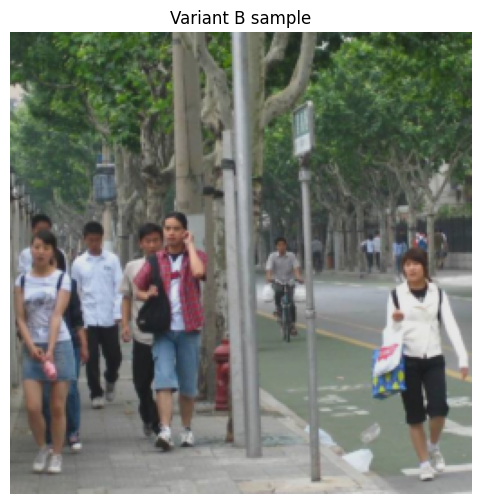

Variant B box prior: {'aspect_lo': 1.5846402645111084, 'aspect_hi': 8.046124458312988, 'area_lo': 0.01066393032670021, 'area_hi': 0.44472262263298035, 'log_aspect_mu': 1.2705860137939453, 'log_aspect_std': 0.3142496347427368, 'log_area_mu': -2.060981035232544, 'log_area_std': 0.7931501269340515}


In [10]:
if RUN_VARIANT_B:
    loader_trainB = DataLoader(trainB, batch_size=BATCH_SIZE_B, shuffle=True, num_workers=0, collate_fn=collate_fn)
    loader_valB = DataLoader(valB, batch_size=BATCH_SIZE_B, shuffle=False, num_workers=0, collate_fn=collate_fn)

    imgs, targets = next(iter(loader_trainB))
    print("Batch size:", len(imgs), "| image tensor:", imgs[0].shape)
    print("Example target keys:", targets[0].keys())
    print("Boxes:", targets[0]["boxes"].shape, "| Masks:", targets[0]["masks"].shape)

    plt.figure(figsize=(6, 6))
    plt.imshow(imgs[0].permute(1, 2, 0).numpy())
    plt.title("Variant B sample")
    plt.axis("off")
    show_and_close()


def compute_box_prior(dataset, img_size: int):
    aspects, areas = [], []
    for i in range(len(dataset)):
        _, tgt = dataset[i]
        boxes = tgt["boxes"].float() / float(img_size)
        if boxes.numel() == 0:
            continue
        w = (boxes[:, 2] - boxes[:, 0]).clamp(min=1e-6)
        h = (boxes[:, 3] - boxes[:, 1]).clamp(min=1e-6)
        aspects.extend((h / w).cpu().tolist())
        areas.extend((h * w).cpu().tolist())
    if len(aspects) == 0:
        return None
    aspects = np.asarray(aspects, dtype=np.float32)
    areas = np.asarray(areas, dtype=np.float32)
    q = np.quantile
    prior = {
        "aspect_lo": float(max(0.25, q(aspects, 0.02) * 0.85)),
        "aspect_hi": float(q(aspects, 0.98) * 1.15),
        "area_lo": float(max(1e-4, q(areas, 0.02) * 0.75)),
        "area_hi": float(min(0.95, q(areas, 0.98) * 1.25)),
        "log_aspect_mu": float(np.log(np.median(aspects))),
        "log_aspect_std": float(max(0.15, np.std(np.log(aspects + 1e-8)))),
        "log_area_mu": float(np.log(np.median(areas))),
        "log_area_std": float(max(0.25, np.std(np.log(areas + 1e-8)))),
    }
    return prior

BOX_PRIOR_B = compute_box_prior(trainB, IMG_SIZE_B)
print("Variant B box prior:", BOX_PRIOR_B)

In [11]:
def box_cxcywh_to_xyxy(box: torch.Tensor) -> torch.Tensor:
    cx, cy, w, h = box.unbind(-1)
    x1 = cx - 0.5 * w
    y1 = cy - 0.5 * h
    x2 = cx + 0.5 * w
    y2 = cy + 0.5 * h
    return torch.stack([x1, y1, x2, y2], dim=-1)

def box_xyxy_to_cxcywh(box: torch.Tensor) -> torch.Tensor:
    x1, y1, x2, y2 = box.unbind(-1)
    w = (x2 - x1).clamp(min=1e-6)
    h = (y2 - y1).clamp(min=1e-6)
    cx = x1 + 0.5 * w
    cy = y1 + 0.5 * h
    return torch.stack([cx, cy, w, h], dim=-1)

def box_iou_xyxy(a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
    N, M = a.shape[0], b.shape[0]
    if N == 0 or M == 0:
        return torch.zeros((N, M), device=a.device)

    a_ = a[:, None, :]
    b_ = b[None, :, :]

    inter_x1 = torch.maximum(a_[..., 0], b_[..., 0])
    inter_y1 = torch.maximum(a_[..., 1], b_[..., 1])
    inter_x2 = torch.minimum(a_[..., 2], b_[..., 2])
    inter_y2 = torch.minimum(a_[..., 3], b_[..., 3])

    inter_w = (inter_x2 - inter_x1).clamp(min=0.0)
    inter_h = (inter_y2 - inter_y1).clamp(min=0.0)
    inter = inter_w * inter_h

    area_a = (a_[..., 2] - a_[..., 0]).clamp(min=0) * (a_[..., 3] - a_[..., 1]).clamp(min=0)
    area_b = (b_[..., 2] - b_[..., 0]).clamp(min=0) * (b_[..., 3] - b_[..., 1]).clamp(min=0)
    union = area_a + area_b - inter + 1e-9
    return inter / union

def generalized_box_iou_xyxy(a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
    if a.numel() == 0 or b.numel() == 0:
        return torch.zeros((a.shape[0], b.shape[0]), device=a.device)

    iou = box_iou_xyxy(a, b)

    a_ = a[:, None, :]
    b_ = b[None, :, :]

    xc1 = torch.minimum(a_[..., 0], b_[..., 0])
    yc1 = torch.minimum(a_[..., 1], b_[..., 1])
    xc2 = torch.maximum(a_[..., 2], b_[..., 2])
    yc2 = torch.maximum(a_[..., 3], b_[..., 3])

    area_c = (xc2 - xc1).clamp(min=0) * (yc2 - yc1).clamp(min=0) + 1e-9

    inter_x1 = torch.maximum(a_[..., 0], b_[..., 0])
    inter_y1 = torch.maximum(a_[..., 1], b_[..., 1])
    inter_x2 = torch.minimum(a_[..., 2], b_[..., 2])
    inter_y2 = torch.minimum(a_[..., 3], b_[..., 3])
    inter = (inter_x2 - inter_x1).clamp(min=0) * (inter_y2 - inter_y1).clamp(min=0)

    area_a = (a_[..., 2] - a_[..., 0]).clamp(min=0) * (a_[..., 3] - a_[..., 1]).clamp(min=0)
    area_b = (b_[..., 2] - b_[..., 0]).clamp(min=0) * (b_[..., 3] - b_[..., 1]).clamp(min=0)
    union = area_a + area_b - inter + 1e-9

    return iou - (area_c - union) / area_c

class ConvNormAct(nn.Module):
    def __init__(self, c_in: int, c_out: int, k: int = 3, s: int = 1, p: Optional[int] = None):
        super().__init__()
        if p is None:
            p = k // 2
        self.block = nn.Sequential(
            nn.Conv2d(c_in, c_out, kernel_size=k, stride=s, padding=p, bias=False),
            nn.BatchNorm2d(c_out),
            nn.GELU(),
        )

    def forward(self, x: torch.Tensor):
        return self.block(x)

class VisualTokensBackbone(nn.Module):
    def __init__(self, img_size: int, patch: int, dim: int, in_chans: int = 3):
        super().__init__()
        assert patch % 4 == 0, "patch should be divisible by 4 for the conv stem"
        proj_stride = max(1, patch // 4)

        self.stem1 = ConvNormAct(in_chans, 32, k=3, s=2)
        self.stem2 = ConvNormAct(32, 64, k=3, s=2)
        self.proj = nn.Sequential(
            ConvNormAct(64, dim, k=proj_stride, s=proj_stride, p=0),
            nn.Conv2d(dim, dim, kernel_size=1, stride=1, padding=0),
        )

        Hp = img_size // patch
        Wp = img_size // patch
        self.Hp, self.Wp = Hp, Wp
        self.S = Hp * Wp
        self.pos = nn.Parameter(torch.zeros(1, self.S, dim))
        nn.init.trunc_normal_(self.pos, std=0.02)

    def forward(self, x: torch.Tensor):
        x1 = self.stem1(x)
        x2 = self.stem2(x1)
        feat = self.proj(x2)
        tokens = feat.flatten(2).transpose(1, 2) + self.pos
        return tokens, feat, x2, (self.Hp, self.Wp)

class QueryDecoderLayer(nn.Module):
    def __init__(self, dim: int, heads: int, mlp_ratio: float = 4.0, drop: float = 0.0):
        super().__init__()
        self.self_attn = nn.MultiheadAttention(dim, heads, batch_first=True, dropout=drop)
        self.cross_attn = nn.MultiheadAttention(dim, heads, batch_first=True, dropout=drop)
        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)
        self.norm3 = nn.LayerNorm(dim)
        hidden = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(
            nn.Linear(dim, hidden),
            nn.GELU(),
            nn.Dropout(drop),
            nn.Linear(hidden, dim),
            nn.Dropout(drop),
        )

    def forward(self, q: torch.Tensor, mem: torch.Tensor, return_cross_attn: bool = False):
        q2, _ = self.self_attn(self.norm1(q), self.norm1(q), self.norm1(q), need_weights=False)
        q = q + q2
        qn = self.norm2(q)
        m = mem
        q2, attn = self.cross_attn(qn, m, m, need_weights=return_cross_attn, average_attn_weights=False)
        q = q + q2
        q = q + self.mlp(self.norm3(q))
        return q, attn

def soft_box_prior_from_cxcywh(boxes_cxcywh: torch.Tensor, H: int, W: int, sharpness: float = 20.0):
    B, Q, _ = boxes_cxcywh.shape
    y = torch.linspace(0.0, 1.0, H, device=boxes_cxcywh.device).view(1, 1, H, 1)
    x = torch.linspace(0.0, 1.0, W, device=boxes_cxcywh.device).view(1, 1, 1, W)
    cx = boxes_cxcywh[..., 0].view(B, Q, 1, 1)
    cy = boxes_cxcywh[..., 1].view(B, Q, 1, 1)
    bw = boxes_cxcywh[..., 2].clamp(min=1e-3).view(B, Q, 1, 1)
    bh = boxes_cxcywh[..., 3].clamp(min=1e-3).view(B, Q, 1, 1)
    dx = (torch.abs(x - cx) / (0.5 * bw + 1e-6))
    dy = (torch.abs(y - cy) / (0.5 * bh + 1e-6))
    return torch.sigmoid(sharpness * (1.0 - torch.maximum(dx, dy)))

class MiniQueryDetMask(nn.Module):
    def __init__(
        self,
        img_size: int = 256,
        patch: int = 8,
        dim: int = 128,
        heads: int = 4,
        num_queries: int = 16,
        num_classes: int = 1,
        dec_layers: int = 2,
        use_mask: bool = False,
    ):
        super().__init__()
        self.visual = VisualTokensBackbone(img_size=img_size, patch=patch, dim=dim, in_chans=3)
        self.use_mask = use_mask
        self.num_classes = num_classes

        self.query_embed = nn.Parameter(torch.zeros(1, num_queries, dim))
        nn.init.trunc_normal_(self.query_embed, std=0.02)

        self.decoder = nn.ModuleList([QueryDecoderLayer(dim=dim, heads=heads, mlp_ratio=4.0, drop=0.1) for _ in range(dec_layers)])
        self.dec_norm = nn.LayerNorm(dim)

        self.objectness_head = nn.Linear(dim, 1)
        self.box_head = nn.Sequential(
            nn.Linear(dim, dim),
            nn.GELU(),
            nn.Linear(dim, dim),
            nn.GELU(),
            nn.Linear(dim, 4),
        )

        if use_mask:
            c_mid = max(dim // 2, 32)
            c_out = max(dim // 4, 32)
            self.mask_feat_proj = nn.Sequential(
                ConvNormAct(dim, dim, k=3, s=1),
                nn.ConvTranspose2d(dim, c_mid, kernel_size=2, stride=2),
                nn.GELU(),
                ConvNormAct(c_mid, c_out, k=3, s=1),
            )
            self.mask_skip_proj = nn.Sequential(
                nn.Conv2d(64, c_out, kernel_size=1, stride=1, padding=0),
                nn.GELU(),
            )
            self.mask_query_proj = nn.Sequential(
                nn.Linear(dim, dim),
                nn.GELU(),
                nn.Linear(dim, c_out),
            )

    def forward(self, images: torch.Tensor, return_attn: bool = False):
        mem, feat_map, skip_map, (Hp, Wp) = self.visual(images)
        B = mem.shape[0]
        q = self.query_embed.expand(B, -1, -1)

        cross_attn_maps = []
        for i, layer in enumerate(self.decoder):
            q, attn = layer(q, mem, return_cross_attn=(return_attn and i == 0))
            if attn is not None:
                cross_attn_maps.append(attn)

        q = self.dec_norm(q)

        objectness = self.objectness_head(q).squeeze(-1)
        boxes = torch.sigmoid(self.box_head(q))
        out = {"pred_logits": objectness, "pred_boxes": boxes, "Hp": Hp, "Wp": Wp}

        if self.use_mask:
            fm = self.mask_feat_proj(feat_map)
            skip = self.mask_skip_proj(skip_map)
            if fm.shape[-2:] != skip.shape[-2:]:
                fm = F.interpolate(fm, size=skip.shape[-2:], mode="bilinear", align_corners=False)
            fm = fm + skip
            qmask = self.mask_query_proj(q)
            mask_logits = torch.einsum("bqd,bdhw->bqhw", qmask, fm)
            box_prior = soft_box_prior_from_cxcywh(boxes, fm.shape[-2], fm.shape[-1], sharpness=24.0)
            mask_logits = mask_logits + 1.0 * (2.0 * box_prior - 1.0)
            out["pred_masks_lowres"] = mask_logits
            out["mask_hw"] = (fm.shape[-2], fm.shape[-1])

        if return_attn and cross_attn_maps:
            out["cross_attn_first_layer"] = cross_attn_maps[0].detach()

        return out

In [12]:
def sigmoid_focal_loss_binary(logits: torch.Tensor, targets: torch.Tensor, alpha: float = 0.25, gamma: float = 2.0):
    prob = torch.sigmoid(logits)
    ce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
    p_t = prob * targets + (1.0 - prob) * (1.0 - targets)
    alpha_t = alpha * targets + (1.0 - alpha) * (1.0 - targets)
    loss = alpha_t * ((1.0 - p_t) ** gamma) * ce
    return loss

def build_cost_matrix(
    pred_logits: torch.Tensor,
    pred_boxes_cxcywh: torch.Tensor,
    tgt_boxes_xyxy: torch.Tensor,
    obj_cost: float = 1.0,
    l1_cost: float = 4.0,
    giou_cost: float = 2.0,
):
    Q = pred_boxes_cxcywh.shape[0]
    T = tgt_boxes_xyxy.shape[0]
    if T == 0:
        return torch.zeros((Q, 0), device=pred_boxes_cxcywh.device)

    tgt_boxes_cxcywh = box_xyxy_to_cxcywh(tgt_boxes_xyxy)
    pred_obj = pred_logits.sigmoid().unsqueeze(1).expand(Q, T)
    cost_obj = -pred_obj

    pred_cxcywh = pred_boxes_cxcywh[:, None, :]
    tgt_cxcywh = tgt_boxes_cxcywh[None, :, :]
    cost_l1 = torch.abs(pred_cxcywh - tgt_cxcywh).sum(dim=-1)

    pred_xyxy = box_cxcywh_to_xyxy(pred_boxes_cxcywh)
    giou = generalized_box_iou_xyxy(pred_xyxy, tgt_boxes_xyxy)
    cost_giou = 1.0 - giou

    return obj_cost * cost_obj + l1_cost * cost_l1 + giou_cost * cost_giou

def greedy_match(cost: torch.Tensor):
    Q, T = cost.shape
    if T == 0:
        return np.array([], dtype=np.int64), np.array([], dtype=np.int64)

    cost_np = cost.detach().cpu().numpy().copy()
    used_q, used_t, pairs = set(), set(), []
    for _ in range(min(Q, T)):
        i, j = np.unravel_index(np.argmin(cost_np), cost_np.shape)
        if i in used_q or j in used_t:
            cost_np[i, j] = np.inf
            continue
        pairs.append((i, j))
        used_q.add(i)
        used_t.add(j)
        cost_np[i, :] = np.inf
        cost_np[:, j] = np.inf

    if len(pairs) == 0:
        return np.array([], dtype=np.int64), np.array([], dtype=np.int64)
    qi = np.array([p[0] for p in pairs], dtype=np.int64)
    tj = np.array([p[1] for p in pairs], dtype=np.int64)
    return qi, tj

def hungarian_match(cost: torch.Tensor):
    cost_np = cost.detach().cpu().numpy()
    qi, tj = linear_sum_assignment(cost_np)
    return qi.astype(np.int64), tj.astype(np.int64)

def match_predictions_to_targets(pred_logits, pred_boxes_cxcywh, targets, img_size: int):
    B, Q, _ = pred_boxes_cxcywh.shape
    matches = []
    for b in range(B):
        tgt = targets[b]
        boxes_xyxy = tgt["boxes"].to(pred_boxes_cxcywh.device) / float(img_size)
        cost = build_cost_matrix(pred_logits[b], pred_boxes_cxcywh[b], boxes_xyxy)
        if cost.shape[1] == 0:
            matches.append((np.array([], np.int64), np.array([], np.int64)))
            continue
        if HAS_SCIPY:
            qi, tj = hungarian_match(cost)
        else:
            qi, tj = greedy_match(cost)
        matches.append((qi, tj))
    return matches

def dice_loss(logits: torch.Tensor, targets: torch.Tensor, eps: float = 1e-6):
    probs = torch.sigmoid(logits)
    num = 2 * (probs * targets).sum(dim=[1, 2])
    den = probs.sum(dim=[1, 2]) + targets.sum(dim=[1, 2]) + eps
    return 1.0 - (num / den)

def duplicate_query_penalty(pred_logits: torch.Tensor, pred_boxes_cxcywh: torch.Tensor):
    probs = pred_logits.sigmoid()
    B, Q = probs.shape
    if Q <= 1:
        return torch.tensor(0.0, device=pred_logits.device)
    boxes_xyxy = box_cxcywh_to_xyxy(pred_boxes_cxcywh.view(-1, 4)).view(B, Q, 4).clamp(0, 1)
    losses = []
    for b in range(B):
        iou = box_iou_xyxy(boxes_xyxy[b], boxes_xyxy[b])
        eye = torch.eye(Q, device=pred_logits.device, dtype=torch.bool)
        iou = iou.masked_fill(eye, 0.0)
        score_outer = probs[b][:, None] * probs[b][None, :]
        losses.append((iou * score_outer).sum() / max(1, Q * (Q - 1)))
    return torch.stack(losses).mean()

def compute_losses(outputs: Dict, targets: List[Dict], img_size: int, use_mask: bool):
    pred_logits = outputs["pred_logits"]
    pred_boxes = outputs["pred_boxes"]
    B, Q, _ = pred_boxes.shape

    matches = match_predictions_to_targets(pred_logits, pred_boxes, targets, img_size=img_size)

    tgt_obj = torch.zeros((B, Q), dtype=torch.float32, device=pred_boxes.device)
    for b, (qi, tj) in enumerate(matches):
        if len(qi) == 0:
            continue
        qi_t = torch.from_numpy(qi).to(pred_boxes.device)
        tgt_obj[b, qi_t] = 1.0

    loss_cls = sigmoid_focal_loss_binary(pred_logits, tgt_obj, alpha=0.20, gamma=2.0).mean()

    loss_bbox = torch.tensor(0.0, device=pred_boxes.device)
    loss_giou = torch.tensor(0.0, device=pred_boxes.device)
    n_match = 0
    for b, (qi, tj) in enumerate(matches):
        if len(qi) == 0:
            continue
        qi_t = torch.from_numpy(qi).to(pred_boxes.device)
        tj_t = torch.from_numpy(tj).to(pred_boxes.device)
        pred_c = pred_boxes[b, qi_t]
        pred_xy = box_cxcywh_to_xyxy(pred_c)
        tgt_xy = (targets[b]["boxes"].to(pred_boxes.device) / float(img_size))[tj_t]
        tgt_c = box_xyxy_to_cxcywh(tgt_xy)
        loss_bbox = loss_bbox + F.l1_loss(pred_c, tgt_c, reduction="sum")
        giou = generalized_box_iou_xyxy(pred_xy, tgt_xy)
        if giou.numel() > 0:
            loss_giou = loss_giou + (1.0 - torch.diag(giou)).sum()
        n_match += len(qi)
    if n_match > 0:
        loss_bbox = loss_bbox / n_match
        loss_giou = loss_giou / n_match

    loss_mask = torch.tensor(0.0, device=pred_boxes.device)
    loss_dice = torch.tensor(0.0, device=pred_boxes.device)
    if use_mask:
        pm = outputs["pred_masks_lowres"]
        Hp, Wp = outputs.get("mask_hw", (outputs["Hp"], outputs["Wp"]))
        matched_batches = 0
        for b, (qi, tj) in enumerate(matches):
            if len(qi) == 0:
                continue
            qi_t = torch.from_numpy(qi).to(pred_boxes.device)
            tj_t = torch.from_numpy(tj).to(pred_boxes.device)

            gt_masks = targets[b]["masks"].to(pred_boxes.device).float()[tj_t]
            gt_low = F.interpolate(gt_masks.unsqueeze(1), size=(Hp, Wp), mode="nearest").squeeze(1)
            pred_low = pm[b, qi_t]

            pos_frac = gt_low.mean().clamp(min=0.02, max=0.98)
            pos_weight = ((1.0 - pos_frac) / pos_frac).detach()
            loss_mask = loss_mask + F.binary_cross_entropy_with_logits(pred_low, gt_low, pos_weight=pos_weight, reduction="mean")
            loss_dice = loss_dice + dice_loss(pred_low, gt_low).mean()
            matched_batches += 1

        loss_mask = loss_mask / max(1, matched_batches)
        loss_dice = loss_dice / max(1, matched_batches)

    loss_dup = duplicate_query_penalty(pred_logits, pred_boxes)
    total = 2.25 * loss_cls + 5.0 * loss_bbox + 2.0 * loss_giou + 0.10 * loss_dup + (2.5 * loss_mask + 2.5 * loss_dice if use_mask else 0.0)
    return {"total": total, "cls": loss_cls, "bbox": loss_bbox, "iou": loss_giou, "mask": loss_mask, "dice": loss_dice}, matches

In [13]:
def box_prior_keep_mask(boxes_xyxy: torch.Tensor, box_prior: Optional[Dict]):
    if box_prior is None or boxes_xyxy.numel() == 0:
        return torch.ones((boxes_xyxy.shape[0],), dtype=torch.bool, device=boxes_xyxy.device)
    w = (boxes_xyxy[:, 2] - boxes_xyxy[:, 0]).clamp(min=1e-6)
    h = (boxes_xyxy[:, 3] - boxes_xyxy[:, 1]).clamp(min=1e-6)
    aspect = h / w
    area = h * w
    keep = (
        (aspect >= box_prior["aspect_lo"]) & (aspect <= box_prior["aspect_hi"]) &
        (area >= box_prior["area_lo"]) & (area <= box_prior["area_hi"])
    )
    return keep

def box_prior_soft_score(boxes_xyxy: torch.Tensor, box_prior: Optional[Dict]):
    if box_prior is None or boxes_xyxy.numel() == 0:
        return torch.ones((boxes_xyxy.shape[0],), dtype=torch.float32, device=boxes_xyxy.device)
    w = (boxes_xyxy[:, 2] - boxes_xyxy[:, 0]).clamp(min=1e-6)
    h = (boxes_xyxy[:, 3] - boxes_xyxy[:, 1]).clamp(min=1e-6)
    aspect = h / w
    area = h * w
    za = (torch.log(aspect) - float(box_prior["log_aspect_mu"])) / float(box_prior["log_aspect_std"])
    zz = (torch.log(area) - float(box_prior["log_area_mu"])) / float(box_prior["log_area_std"])
    score = torch.exp(-0.5 * (0.6 * za.pow(2) + 0.4 * zz.pow(2)))
    return score.clamp(0.05, 1.0)

def mask_confidence_from_lowres(mask_lowres: torch.Tensor):
    if mask_lowres.numel() == 0:
        return torch.zeros((0,), dtype=torch.float32, device=mask_lowres.device)
    probs = mask_lowres.sigmoid().flatten(1)
    k = max(8, probs.shape[1] // 8)
    topk = probs.topk(k=min(k, probs.shape[1]), dim=1).values
    return topk.mean(dim=1).clamp(0.0, 1.0)

def select_pred_indices(logits_b: torch.Tensor, boxes_b: torch.Tensor, pred_masks_lowres_b: Optional[torch.Tensor] = None, score_thr: float = 0.35, nms_thr: float = 0.5, max_keep: int = 10, box_prior: Optional[Dict] = None, allow_fallback: bool = False):
    base_scores = logits_b.sigmoid()
    boxes_xyxy_all = box_cxcywh_to_xyxy(boxes_b).clamp(0, 1)
    prior_soft = box_prior_soft_score(boxes_xyxy_all, box_prior)
    scores = base_scores * (prior_soft ** 0.6)
    if pred_masks_lowres_b is not None:
        mask_conf = mask_confidence_from_lowres(pred_masks_lowres_b)
        scores = scores * (0.55 + 0.45 * mask_conf)

    idx = torch.where(scores >= score_thr)[0]
    if idx.numel() == 0 and allow_fallback:
        idx = torch.topk(scores, k=min(2, scores.numel())).indices
    if idx.numel() == 0:
        return idx, scores[idx]

    boxes_xyxy = boxes_xyxy_all[idx]
    hard_keep = box_prior_keep_mask(boxes_xyxy, box_prior)
    if hard_keep.sum().item() > 0:
        idx = idx[hard_keep]
        boxes_xyxy = boxes_xyxy[hard_keep]
    if idx.numel() == 0:
        return idx, scores[idx]

    refined_scores = scores[idx]
    keep = torchvision.ops.nms(boxes_xyxy, refined_scores, nms_thr)
    if max_keep is not None:
        keep = keep[:max_keep]
    return idx[keep], refined_scores[keep]

def train_one_epoch_query(model, loader, optimizer, scaler=None, use_mask: bool = False):
    model.train()
    logs = {"total": [], "cls": [], "bbox": [], "iou": [], "mask": [], "dice": []}
    for imgs, targets in tqdm(loader, desc="trainB", leave=False):
        xb = torch.stack([im.to(device) for im in imgs], dim=0)
        tg = [{k: v.to(device) if torch.is_tensor(v) else v for k, v in t.items()} for t in targets]
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=(scaler is not None and device.type == "cuda")):
            out = model(xb, return_attn=False)
            losses, _ = compute_losses(out, tg, img_size=IMG_SIZE_B, use_mask=use_mask)
            loss = losses["total"]

        if scaler is None or device.type != "cuda":
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        else:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

        for k in logs.keys():
            logs[k].append(float(losses[k].detach().cpu().item()))
    return {k: float(np.mean(v)) for k, v in logs.items()}

def greedy_match_pairs(iou_mat: torch.Tensor, iou_thr: float = 0.5):
    pairs = []
    if iou_mat.numel() == 0:
        return pairs
    cand = torch.nonzero(iou_mat >= iou_thr, as_tuple=False)
    if cand.numel() == 0:
        return pairs
    vals = iou_mat[cand[:, 0], cand[:, 1]]
    order = torch.argsort(vals, descending=True)
    used_p, used_t = set(), set()
    for k in order.tolist():
        p = int(cand[k, 0].item())
        t = int(cand[k, 1].item())
        if p in used_p or t in used_t:
            continue
        used_p.add(p)
        used_t.add(t)
        pairs.append((p, t, float(iou_mat[p, t].item())))
    return pairs

@torch.no_grad()
def eval_query_metrics(model, loader, use_mask: bool, score_thr: float = 0.35, nms_thr: float = 0.5, max_keep: int = 6, box_prior: Optional[Dict] = None):
    model.eval()
    tp_ious, mask_ious, dup_counts = [], [], []
    total_tp = total_fp = total_fn = 0

    for imgs, targets in tqdm(loader, desc="evalB", leave=False):
        xb = torch.stack([im.to(device) for im in imgs], dim=0)
        out = model(xb, return_attn=False)

        logits = out["pred_logits"]
        boxes = out["pred_boxes"]

        B = xb.shape[0]
        for b in range(B):
            gt_boxes = targets[b]["boxes"].to(device) / float(IMG_SIZE_B)
            gt_masks = targets[b]["masks"].to(device).float() if use_mask else None

            fg_idx, fg_scores = select_pred_indices(logits[b], boxes[b], pred_masks_lowres_b=(out["pred_masks_lowres"][b] if use_mask and "pred_masks_lowres" in out else None), score_thr=score_thr, nms_thr=nms_thr, max_keep=max_keep, box_prior=box_prior, allow_fallback=False)

            if gt_boxes.shape[0] == 0:
                total_fp += int(fg_idx.numel())
                continue

            if fg_idx.numel() == 0:
                total_fn += int(gt_boxes.shape[0])
                continue

            pb = box_cxcywh_to_xyxy(boxes[b, fg_idx]).clamp(0, 1)
            iou_mat = box_iou_xyxy(pb, gt_boxes)
            matches = greedy_match_pairs(iou_mat, iou_thr=0.5)

            tp = len(matches)
            fp = int(fg_idx.numel()) - tp
            fn = int(gt_boxes.shape[0]) - tp
            total_tp += tp
            total_fp += fp
            total_fn += fn

            tp_ious.extend([m[2] for m in matches])
            dup_counts.append(max(0, int(fg_idx.numel()) - tp))

            if use_mask and "pred_masks_lowres" in out and len(matches):
                pm_low = out["pred_masks_lowres"][b, fg_idx]
                pm = F.interpolate(pm_low.unsqueeze(1), size=(IMG_SIZE_B, IMG_SIZE_B), mode="bilinear", align_corners=False).squeeze(1)
                pm_bin = (pm.sigmoid() >= 0.5).float()
                for p_i, gt_id, _ in matches:
                    gt = gt_masks[gt_id]
                    predm = pm_bin[p_i]
                    inter = (predm * gt).sum().item()
                    union = ((predm + gt) > 0).float().sum().item() + 1e-9
                    mask_ious.append(inter / union)

    precision = total_tp / max(1, total_tp + total_fp)
    recall = total_tp / max(1, total_tp + total_fn)

    return {
        "mean_box_iou": float(np.mean(tp_ious)) if len(tp_ious) else float("nan"),
        "precision_at_0p5": float(precision),
        "recall_at_0p5": float(recall),
        "mask_iou": float(np.mean(mask_ious)) if len(mask_ious) else float("nan"),
        "dup_mean": float(np.mean(dup_counts)) if len(dup_counts) else 0.0,
        "total_tp": int(total_tp),
        "total_fp": int(total_fp),
        "total_fn": int(total_fn),
    }

def select_query_score(metrics: Dict, use_mask: bool):
    precision = float(metrics.get("precision_at_0p5", 0.0))
    recall = float(metrics.get("recall_at_0p5", 0.0))
    beta2 = 0.75 ** 2
    f_beta = (1 + beta2) * precision * recall / max(1e-9, beta2 * precision + recall)
    score = 1.75 * f_beta + 0.35 * float(np.nan_to_num(metrics.get("mean_box_iou", 0.0)))
    score -= 0.08 * float(metrics.get("dup_mean", 0.0))
    if use_mask:
        score += 0.45 * float(np.nan_to_num(metrics.get("mask_iou", 0.0)))
    return score

def tune_postproc_thresholds(model, loader, use_mask: bool, box_prior: Optional[Dict] = None):
    score_grid = [0.08, 0.12, 0.18, 0.24, 0.32, 0.40]
    nms_grid = [0.35, 0.45, 0.55]
    max_keep_grid = [2, 3, 4, 5]
    best = None
    best_metrics = None
    best_score = float("-inf")
    for score_thr in score_grid:
        for nms_thr in nms_grid:
            for max_keep in max_keep_grid:
                metrics = eval_query_metrics(model, loader, use_mask=use_mask, score_thr=score_thr, nms_thr=nms_thr, max_keep=max_keep, box_prior=box_prior)
                sel = select_query_score(metrics, use_mask=use_mask)
                if sel > best_score:
                    best_score = sel
                    best = {"score_thr": score_thr, "nms_thr": nms_thr, "max_keep": max_keep, "selection_score": sel}
                    best_metrics = metrics
    return best, best_metrics

def run_query_experiment(cfg: Dict):
    model = MiniQueryDetMask(
        img_size=IMG_SIZE_B,
        patch=cfg["patch"],
        dim=cfg["dim"],
        heads=cfg["heads"],
        num_queries=cfg["num_queries"],
        num_classes=1,
        dec_layers=cfg["dec_layers"],
        use_mask=cfg["use_mask"],
    ).to(device)

    params = count_parameters(model)
    S = model.visual.S
    q_cost = estimate_self_attention_cost(seq_len=cfg["num_queries"], dim=cfg["dim"], num_heads=cfg["heads"])
    cross_mem_mb = cfg["heads"] * cfg["num_queries"] * S * 4 / (1024 ** 2)

    est_epoch_sec = estimate_epoch_seconds("B", len(loader_trainB) + len(loader_valB), params_m=params / 1e6, num_queries=cfg["num_queries"], visual_tokens=S)
    print_runtime_hint(f"Variant B / {cfg['name']}", est_epoch_sec * EPOCHS_B)

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR_B, weight_decay=WEIGHT_DECAY_B)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_B)
    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

    history = []
    best_score = float("-inf")
    best_state = None
    exp_start = time.perf_counter()
    epoch_times = []
    for epoch in range(1, EPOCHS_B + 1):
        epoch_start = time.perf_counter()
        tr = train_one_epoch_query(model, loader_trainB, optimizer, scaler=scaler, use_mask=cfg["use_mask"])
        metrics = eval_query_metrics(model, loader_valB, use_mask=cfg["use_mask"], score_thr=0.18, nms_thr=0.45, max_keep=4, box_prior=BOX_PRIOR_B)
        scheduler.step()
        row = {"epoch": epoch, **tr, **metrics}
        row["selection_score"] = select_query_score(metrics, use_mask=cfg["use_mask"])
        history.append(row)
        if row["selection_score"] > best_score:
            best_score = row["selection_score"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        epoch_elapsed = time.perf_counter() - epoch_start
        epoch_times.append(epoch_elapsed)
        eta = np.mean(epoch_times) * max(0, EPOCHS_B - epoch)
        print(f"[{cfg['name']}] ep {epoch:02d}/{EPOCHS_B} | boxIoU={metrics['mean_box_iou']:.3f} prec={metrics['precision_at_0p5']:.3f} rec={metrics['recall_at_0p5']:.3f} mask={metrics['mask_iou']:.3f} | epoch_time={format_seconds(epoch_elapsed)} | eta={format_seconds(eta)}")

    if best_state is not None:
        model.load_state_dict(best_state)

    tuned_postproc, final_metrics = tune_postproc_thresholds(model, loader_valB, use_mask=cfg["use_mask"], box_prior=BOX_PRIOR_B)
    if history:
        history[-1].update({f"best_{k}": v for k, v in final_metrics.items() if isinstance(v, (int, float))})
        history[-1]["best_score_thr"] = tuned_postproc["score_thr"]
        history[-1]["best_nms_thr"] = tuned_postproc["nms_thr"]
        history[-1]["best_max_keep"] = tuned_postproc["max_keep"]
        history[-1]["best_selection_score"] = tuned_postproc["selection_score"]

    print(f"[{cfg['name']}] total elapsed: {format_seconds(time.perf_counter() - exp_start)}")

    return {
        "name": cfg["name"],
        "patch": cfg["patch"],
        "num_queries": cfg["num_queries"],
        "dim": cfg["dim"],
        "heads": cfg["heads"],
        "dec_layers": cfg["dec_layers"],
        "use_mask": cfg["use_mask"],
        "params": params,
        "visual_tokens": S,
        "q_self_attn_mem_mb": q_cost["attn_weights_mem_mb"],
        "cross_attn_mem_mb": cross_mem_mb,
        "history": history,
        "state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
        "postproc": tuned_postproc,
    }

In [14]:
results_B = []
if RUN_VARIANT_B:
    for cfg in QUERY_CONFIGS:
        out = run_query_experiment(cfg)
        results_B.append(out)

    rows = []
    for r in results_B:
        last = r["history"][-1]
        rows.append({
            "name": r["name"],
            "patch": r["patch"],
            "num_queries": r["num_queries"],
            "dim": r["dim"],
            "heads": r["heads"],
            "dec_layers": r["dec_layers"],
            "use_mask": r["use_mask"],
            "params": r["params"],
            "visual_tokens": r["visual_tokens"],
            "q_self_attn_mem_mb": round(r["q_self_attn_mem_mb"], 3),
            "cross_attn_mem_mb": round(r["cross_attn_mem_mb"], 3),
            "mean_box_iou": round(last.get("best_mean_box_iou", last.get("mean_box_iou", float("nan"))), 4),
            "precision@0.5": round(last.get("best_precision_at_0p5", last.get("precision_at_0p5", float("nan"))), 4),
            "recall@0.5": round(last.get("best_recall_at_0p5", last.get("recall_at_0p5", float("nan"))), 4),
            "mask_iou": round(last.get("best_mask_iou", last.get("mask_iou", float("nan"))), 4),
            "dup_mean": round(last.get("best_dup_mean", last.get("dup_mean", 0.0)), 4),
            "score_thr": round(r.get("postproc", {}).get("score_thr", 0.35), 2),
            "nms_thr": round(r.get("postproc", {}).get("nms_thr", 0.50), 2),
            "max_keep": int(r.get("postproc", {}).get("max_keep", 6)),
        })

    if HAS_PANDAS:
        dfB = pd.DataFrame(rows).sort_values("mean_box_iou", ascending=False)
        display(dfB)
        dfB.to_csv("outputs/variant_b/results_b.csv", index=False)
    else:
        print(rows)

Approx runtime for Variant B / q10_p8_d2_dim128_boxonly on CUDA: ~2m 01s (heuristic estimate)


trainB:   0%|          | 0/17 [00:00<?, ?it/s]

evalB:   0%|          | 0/3 [00:00<?, ?it/s]

[q10_p8_d2_dim128_boxonly] ep 01/18 | boxIoU=0.628 prec=0.293 rec=0.447 mask=nan | epoch_time=6s | eta=1m 34s


trainB:   0%|          | 0/17 [00:00<?, ?it/s]

...

evalB:   0%|          | 0/3 [00:00<?, ?it/s]

evalB:   0%|          | 0/3 [00:00<?, ?it/s]

evalB:   0%|          | 0/3 [00:00<?, ?it/s]

[q12_p8_d2_dim128_boxmask] total elapsed: 1m 53s


,name,patch,num_queries,dim,heads,dec_layers,use_mask,params,visual_tokens,q_self_attn_mem_mb,cross_attn_mem_mb,mean_box_iou,precision@0.5,recall@0.5,mask_iou,dup_mean,score_thr,nms_thr,max_keep
1,q12_p8_d2_dim128_boxmask,8,12,128,4,2,True,986469,1024,0.002,0.188,0.6280,0.3725,0.5000,0.3849,1.8824,0.08,0.35,3
0,q10_p8_d2_dim128_boxonly,8,10,128,4,2,False,764453,1024,0.002,0.156,0.6256,0.3171,0.3421,NaN,1.6471,0.08,0.35,3


saved: outputs/variant_b/pred_boxes_0.png


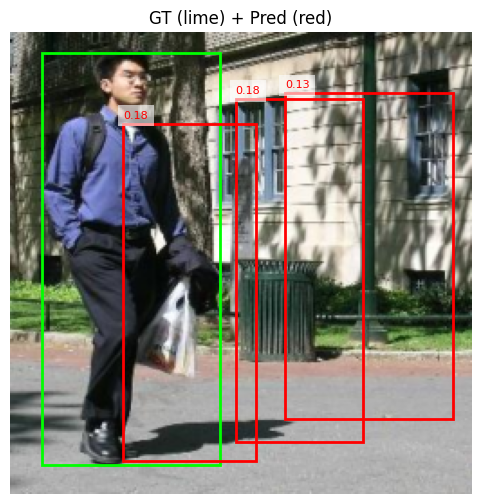

saved: outputs/variant_b/pred_mask_0.png


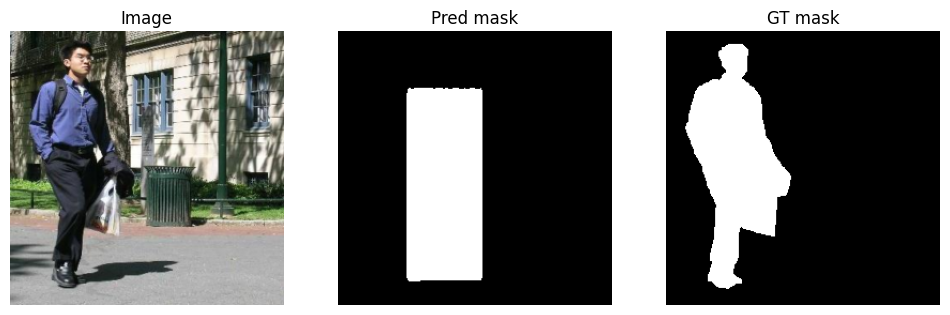

saved: outputs/variant_b/cross_attn_0.png


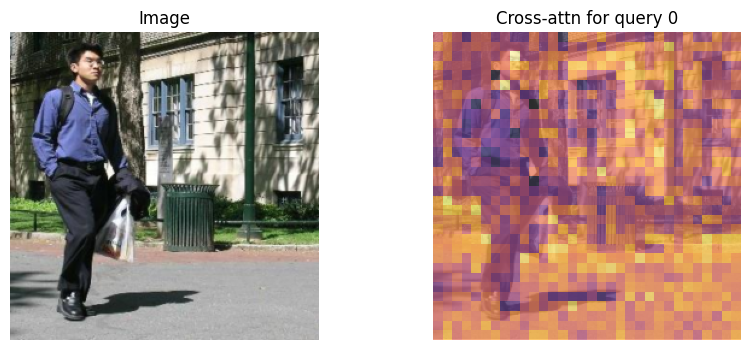

saved: outputs/variant_b/pred_boxes_1.png


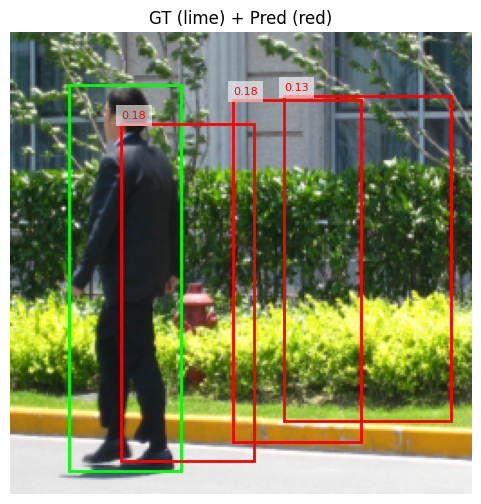

saved: outputs/variant_b/pred_mask_1.png


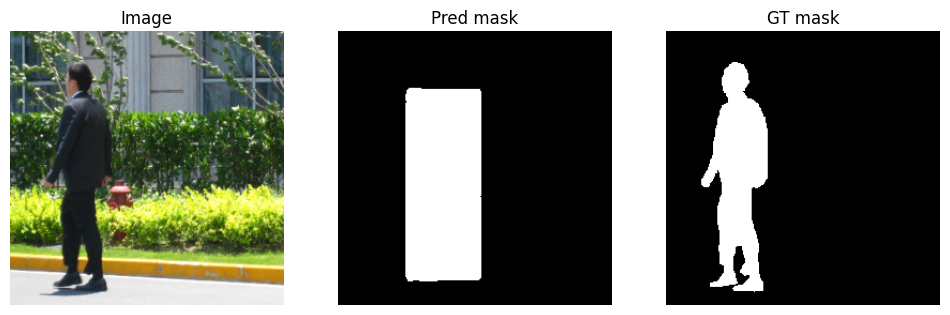

saved: outputs/variant_b/cross_attn_1.png


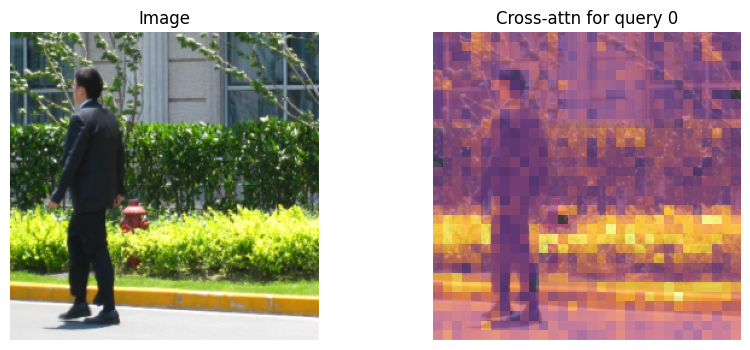

saved: outputs/variant_b/pred_boxes_2.png


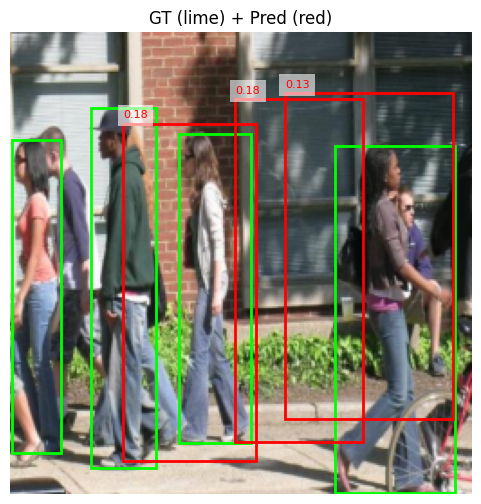

saved: outputs/variant_b/pred_mask_2.png


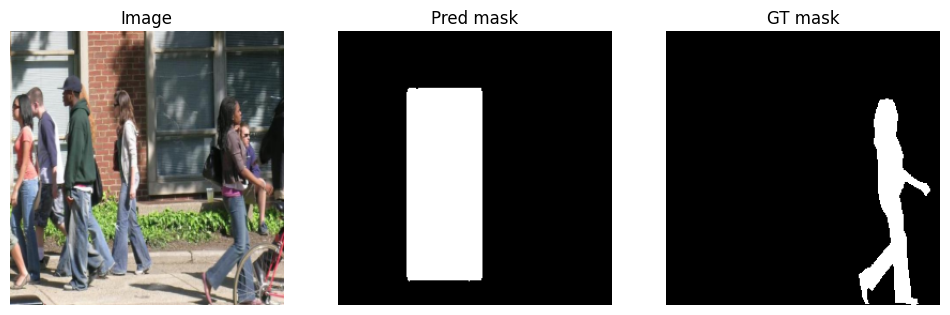

saved: outputs/variant_b/cross_attn_2.png


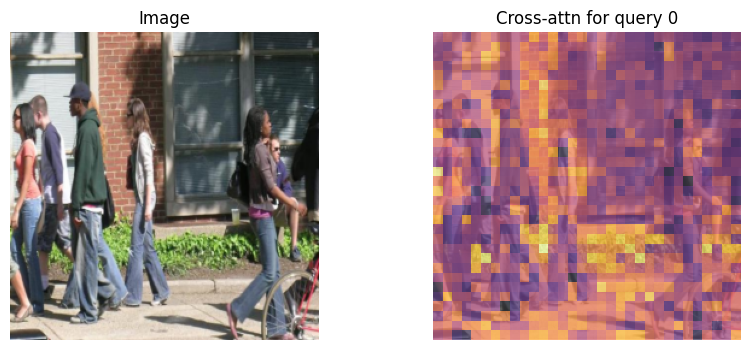

saved: outputs/variant_b/mask_pred_boxes_0.png


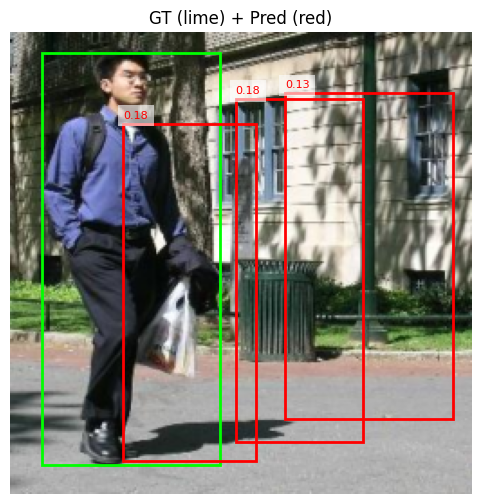

saved: outputs/variant_b/mask_pred_mask_0.png


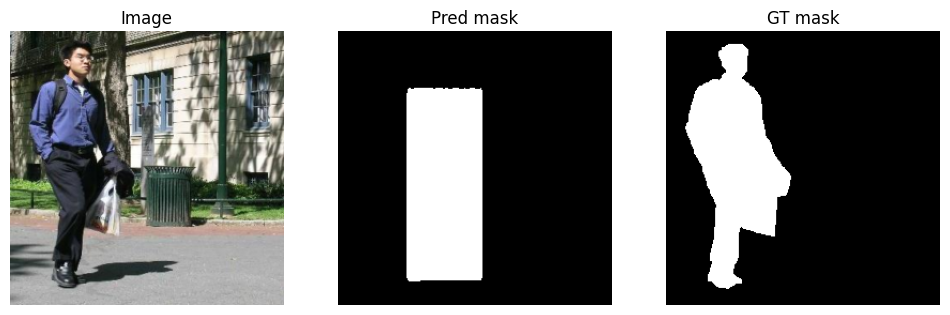

saved: outputs/variant_b/mask_cross_attn_0.png


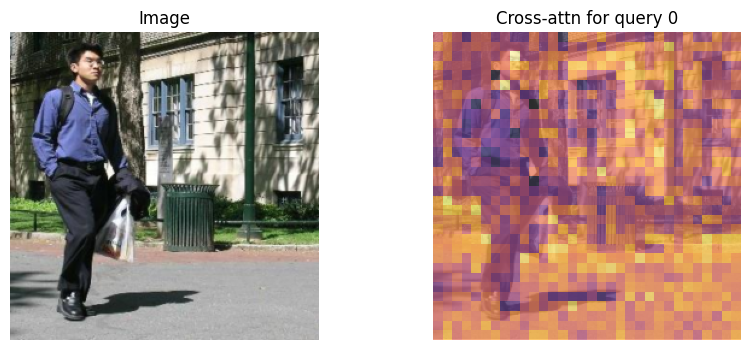

saved: outputs/variant_b/mask_pred_boxes_1.png


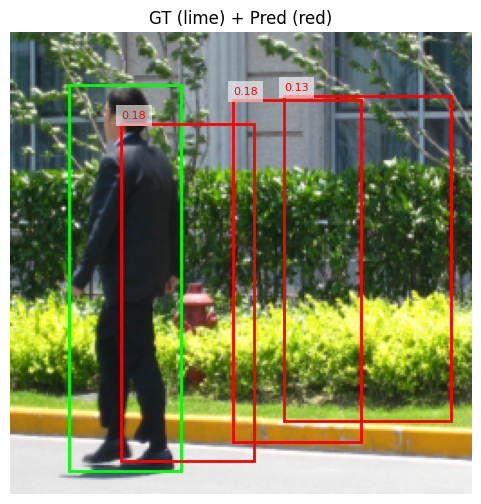

saved: outputs/variant_b/mask_pred_mask_1.png


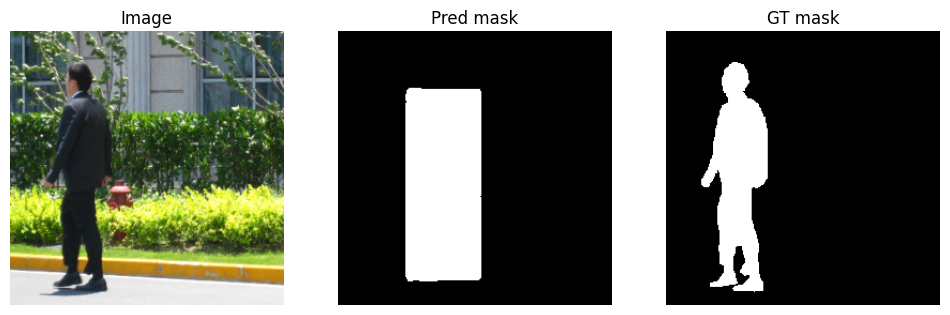

saved: outputs/variant_b/mask_cross_attn_1.png


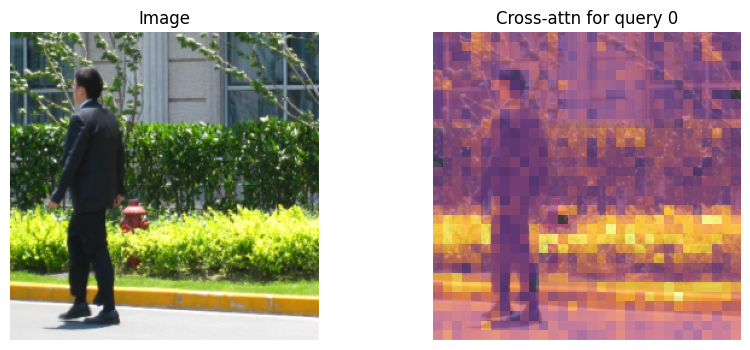

saved: outputs/variant_b/mask_pred_boxes_2.png


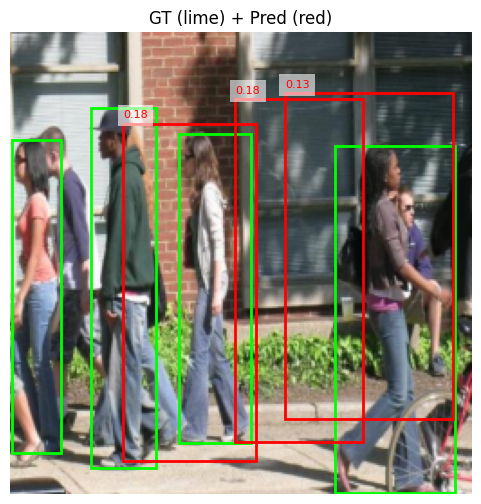

saved: outputs/variant_b/mask_pred_mask_2.png


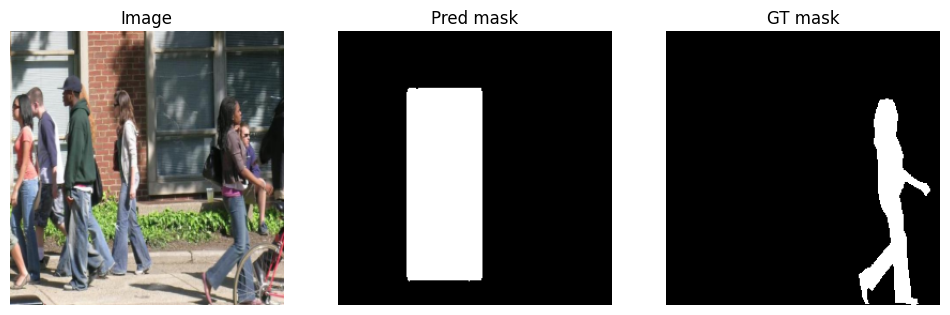

saved: outputs/variant_b/mask_cross_attn_2.png


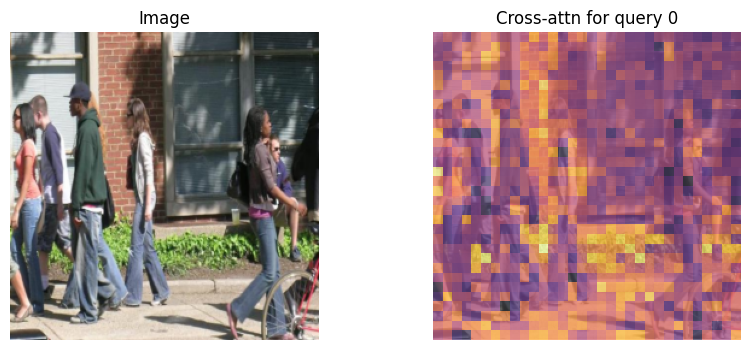

In [15]:
def draw_boxes(ax, boxes_xyxy_px: np.ndarray, color: str):
    for b in boxes_xyxy_px:
        x1, y1, x2, y2 = b
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=2))

@torch.no_grad()
def visualize_variant_b(model: MiniQueryDetMask, loader, max_images: int = 3, score_thr: float = 0.35, nms_thr: float = 0.5, max_keep: int = 6, box_prior: Optional[Dict] = None, prefix: str = ""):
    model.eval()
    shown = 0
    for imgs, targets in loader:
        xb = torch.stack([im.to(device) for im in imgs], dim=0)
        out = model(xb, return_attn=True)

        logits = out["pred_logits"]
        boxes = box_cxcywh_to_xyxy(out["pred_boxes"]).clamp(0, 1) * IMG_SIZE_B
        boxes = boxes.detach().cpu().numpy()

        cross = out.get("cross_attn_first_layer", None)
        Hp, Wp = out["Hp"], out["Wp"]

        for b in range(xb.shape[0]):
            img = xb[b].detach().cpu().permute(1, 2, 0).numpy()
            gt_boxes = targets[b]["boxes"].numpy()
            gt_masks = targets[b]["masks"].numpy() if model.use_mask else None

            keep_idx, keep_scores = select_pred_indices(logits[b], out["pred_boxes"][b], pred_masks_lowres_b=(out["pred_masks_lowres"][b] if model.use_mask and "pred_masks_lowres" in out else None), score_thr=score_thr, nms_thr=nms_thr, max_keep=max_keep, box_prior=box_prior, allow_fallback=True)
            sel_idx = keep_idx.detach().cpu().numpy().tolist()
            pred_boxes = boxes[b][sel_idx] if len(sel_idx) else np.zeros((0, 4), dtype=np.float32)

            fig, ax = plt.subplots(1, 1, figsize=(6, 6))
            ax.imshow(img)
            draw_boxes(ax, gt_boxes, "lime")
            draw_boxes(ax, pred_boxes, "red")
            if len(sel_idx):
                for k, bb in enumerate(pred_boxes):
                    ax.text(bb[0], max(5, bb[1] - 3), f"{float(keep_scores[k]):.2f}", color="red", fontsize=8, bbox=dict(facecolor="white", alpha=0.6, edgecolor="none"))
            ax.set_title("GT (lime) + Pred (red)")
            ax.axis("off")
            save_figure(f"outputs/variant_b/{prefix}pred_boxes_{shown}.png")
            show_and_close()

            if model.use_mask and "pred_masks_lowres" in out and len(sel_idx):
                pm_low = out["pred_masks_lowres"][b, sel_idx]
                pm = F.interpolate(pm_low.unsqueeze(1), size=(IMG_SIZE_B, IMG_SIZE_B), mode="bilinear", align_corners=False).squeeze(1)
                pm = pm.sigmoid().detach().cpu().numpy()

                plt.figure(figsize=(12, 4))
                plt.subplot(1, 3, 1)
                plt.imshow(img)
                plt.title("Image")
                plt.axis("off")
                plt.subplot(1, 3, 2)
                plt.imshow(pm[0] >= 0.5, cmap="gray")
                plt.title("Pred mask")
                plt.axis("off")
                plt.subplot(1, 3, 3)
                gt_idx = 0
                if len(gt_masks):
                    areas = [m.sum() for m in gt_masks]
                    gt_idx = int(np.argmax(areas))
                    plt.imshow(gt_masks[gt_idx], cmap="gray")
                plt.title("GT mask")
                plt.axis("off")
                save_figure(f"outputs/variant_b/{prefix}pred_mask_{shown}.png")
                show_and_close()

            if cross is not None and len(sel_idx):
                q0 = sel_idx[0]
                attn = cross[b]
                heat = attn[:, q0, :].mean(dim=0).reshape(Hp, Wp).detach().cpu().numpy()
                plt.figure(figsize=(10, 4))
                plt.subplot(1, 2, 1)
                plt.imshow(img)
                plt.title("Image")
                plt.axis("off")
                plt.subplot(1, 2, 2)
                plt.imshow(img, alpha=0.6)
                plt.imshow(heat, cmap="inferno", alpha=0.6, extent=(0, IMG_SIZE_B, IMG_SIZE_B, 0))
                plt.title(f"Cross-attn for query {q0}")
                plt.axis("off")
                save_figure(f"outputs/variant_b/{prefix}cross_attn_{shown}.png")
                show_and_close()

            shown += 1
            if shown >= max_images:
                return

if RUN_VARIANT_B and results_B:
    bestB = max(results_B, key=lambda r: r.get("postproc", {}).get("selection_score", r["history"][-1].get("selection_score", float("-inf"))))
    cfg = next(c for c in QUERY_CONFIGS if c["name"] == bestB["name"])

    modelB = MiniQueryDetMask(
        img_size=IMG_SIZE_B,
        patch=cfg["patch"],
        dim=cfg["dim"],
        heads=cfg["heads"],
        num_queries=cfg["num_queries"],
        num_classes=1,
        dec_layers=cfg["dec_layers"],
        use_mask=cfg["use_mask"]
    ).to(device)
    modelB.load_state_dict(bestB["state_dict"])
    visualize_variant_b(modelB, loader_valB, max_images=3, score_thr=bestB.get("postproc", {}).get("score_thr", 0.20), nms_thr=bestB.get("postproc", {}).get("nms_thr", 0.5), max_keep=int(bestB.get("postproc", {}).get("max_keep", 6)), box_prior=BOX_PRIOR_B, prefix="")

    mask_models = [r for r in results_B if r["use_mask"]]
    if mask_models:
        best_mask = max(mask_models, key=lambda r: r["history"][-1].get("best_mask_iou", float("-inf")))
        cfgm = next(c for c in QUERY_CONFIGS if c["name"] == best_mask["name"])
        modelM = MiniQueryDetMask(
            img_size=IMG_SIZE_B,
            patch=cfgm["patch"],
            dim=cfgm["dim"],
            heads=cfgm["heads"],
            num_queries=cfgm["num_queries"],
            num_classes=1,
            dec_layers=cfgm["dec_layers"],
            use_mask=cfgm["use_mask"]
        ).to(device)
        modelM.load_state_dict(best_mask["state_dict"])
        visualize_variant_b(modelM, loader_valB, max_images=3, score_thr=best_mask.get("postproc", {}).get("score_thr", 0.20), nms_thr=best_mask.get("postproc", {}).get("nms_thr", 0.5), max_keep=int(best_mask.get("postproc", {}).get("max_keep", 6)), box_prior=BOX_PRIOR_B, prefix="mask_")


### Variant B — brief analysis notes

- More queries can improve recall, but also increase duplicate detections and no-object predictions.
- Cross-attention maps help show **which image tokens each query attends to**.
- Query-based output is naturally set-like: each query tries to explain one object slot.
- Extending from box-only to box+mask is natural because the same query can also project onto a spatial feature map.
